# UTS Graf Sains Data – Sistem Rekomendasi Berbasis Graf (RetailRocket + Neo4j)

**Alur kerja:** `events.csv` → filter waktu (P1 training, P2 testing) → impor P1 ke Neo4j (Aura) → VSM User & Item → proyeksi graf → cosine similarity → tulis relasi `:SIMILAR` ke graf → KNN item-based (k = 5) → evaluasi Hit@5 & NDCG@5.

**Periode yang dipakai (UTC):**

| | Mulai | Selesai | Lama | Baris | Unix timestamp (ms) |
|---|---|---|---|---|---|
| P1 (training) | 2015-05-18 00:00:00 | 2015-05-25 23:59:59 | 8 hari | 176.376 | 1431907200000 – 1432598399000 |
| P2 (testing)  | 2015-05-26 00:00:00 | 2015-06-01 23:59:59 | 7 hari | 140.752 | 1432598400000 – 1433203199000 |

Data training lebih banyak daripada data testing (176.376 vs 140.752 baris; ±1,25 : 1).

**Catatan data:** `events.csv` (RetailRocket) berisi 2.756.101 event dari 3 Mei sampai 18 September 2015, sehingga contoh periode di soal (2023/2024) tidak berlaku. Kolom `timestamp` berupa Unix epoch **milidetik**. P1 dibatasi 8 hari karena Neo4j AuraDB Free hanya menampung 200.000 simpul (P1 menghasilkan 155.263 simpul); P2 tidak diimpor ke Neo4j, tetapi dibuat lebih pendek daripada P1 agar data training tetap lebih banyak.

**Cara menjalankan ulang:** letakkan `events.csv` (unduh dari Kaggle: retailrocket/ecommerce-dataset) satu folder dengan notebook, siapkan instance Neo4j Aura, lalu jalankan sel dari atas. Password dimasukkan lewat `getpass` dan tidak disimpan di notebook. Query yang dijalankan di Neo4j Aura (tab Query) ada di berkas `*.cypher`, screenshot hasilnya ada di folder `images/`.

In [1]:
!pip install -q "neo4j>=5.20"
import pandas as pd, numpy as np, scipy, sklearn, networkx as nx, neo4j
print("pandas", pd.__version__, "| neo4j", neo4j.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 390.7/390.7 kB 6.9 MB/s eta 0:00:00
pandas 2.2.3 | neo4j 6.4.1


## 1. Koneksi ke Neo4j Aura
Driver `neo4j` (versi 6.x) memakai skema `neo4j+s://` (koneksi terenkripsi untuk Aura). Pada instance Aura versi baru, **username dan nama database sama dengan ID instance**, bukan `neo4j`. Karena itu setiap `execute_query` dan `session` memakai parameter `database_=DB` / `database=DB`. Password diminta lewat `getpass` agar tidak tertulis di notebook.

In [2]:
from getpass import getpass
from neo4j import GraphDatabase

URI = "neo4j+s://5d210996.databases.neo4j.io"
USER = "5d210996"
DB = "5d210996"

driver = GraphDatabase.driver(URI, auth=(USER, getpass("Password Aura: ")))
driver.verify_connectivity()
print("Terhubung ke Aura!")

records, _, _ = driver.execute_query(
    "RETURN 'halo dari Aura' AS pesan", database_=DB
)
print(records[0]["pesan"])

Password Aura: ··········
Terhubung ke Aura!
halo dari Aura


## 2. Wrangling & EDA (Soal 2.1)
### Memuat data dan memeriksa rentang waktu
`timestamp` dikonversi ke `datetime` (`unit="ms"`) untuk mengetahui rentang data: 2015-05-03 03:00 s.d. 2015-09-18 02:59 (UTC), dengan 2.664.312 `view`, 69.332 `addtocart`, 22.457 `transaction`, 1.407.580 visitor dan 235.061 item unik.

In [3]:
import pandas as pd

df = pd.read_csv("events.csv")
df["dt"] = pd.to_datetime(df["timestamp"], unit="ms")

print(df.shape)
print(df["dt"].min(), "sampai", df["dt"].max())
print(df["event"].value_counts())
print("Visitor unik:", df["visitorid"].nunique())
print("Item unik   :", df["itemid"].nunique())
df.head()

(2756101, 6)
2015-05-03 03:00:04.384000 sampai 2015-09-18 02:59:47.788000
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64
Visitor unik: 1407580
Item unik   : 235061


,timestamp,visitorid,event,itemid,transactionid,dt
0,1433221332117,257597,view,355908,NaN,2015-06-02 05:02:12.117
1,1433224214164,992329,view,248676,NaN,2015-06-02 05:50:14.164
2,1433221999827,111016,view,318965,NaN,2015-06-02 05:13:19.827
3,1433221955914,483717,view,253185,NaN,2015-06-02 05:12:35.914
4,1433221337106,951259,view,367447,NaN,2015-06-02 05:02:17.106


### No. 1–2: Filter dua periode dan simpan ke CSV
Data dibagi menjadi **P1** (training, 18–25 Mei 2015) dan **P2** (testing, 26 Mei – 1 Juni 2015) berdasarkan kolom `dt`. P1 dipakai membangun graf dan menghitung similarity; P2 dipakai sebagai *ground truth* evaluasi. Hasilnya disimpan sebagai `events_p1.csv` dan `events_p2.csv`. Periode dipilih agar data training lebih banyak daripada data testing.

`itemid` dikonversi ke tipe `Int64` (nullable) agar tidak terbaca `float` bila ada nilai kosong.

Hasil: **P1 = 176.376 baris** (96.733 visitor, 58.530 item; 171.139 view, 3.998 addtocart, 1.239 transaction) dan **P2 = 140.752 baris** (78.421 visitor, 49.648 item; 136.121 view, 3.463 addtocart, 1.168 transaction). Ada **4.017** visitor yang muncul di P1 dan P2, dan **942** di antaranya punya ≥ 3 item berbeda di P1. Merekalah kandidat evaluasi di bagian 2.2.

In [9]:
P1_START, P1_END = "2015-05-18 00:00:00", "2015-05-25 23:59:59"
P2_START, P2_END = "2015-05-26 00:00:00", "2015-06-01 23:59:59"

df["itemid"] = df["itemid"].astype("Int64")

p1 = df[(df["dt"] >= P1_START) & (df["dt"] <= P1_END)].copy()
p2 = df[(df["dt"] >= P2_START) & (df["dt"] <= P2_END)].copy()

p1.to_csv("events_p1.csv", index=False)
p2.to_csv("events_p2.csv", index=False)

print("P1:", p1.shape, "| visitor:", p1.visitorid.nunique(), "| item:", p1.itemid.nunique())
print("P2:", p2.shape, "| visitor:", p2.visitorid.nunique(), "| item:", p2.itemid.nunique())
print(p1.event.value_counts().to_dict())
print(p2.event.value_counts().to_dict())

both = set(p1.visitorid) & set(p2.visitorid)
print("Visitor di P1 dan P2:", len(both))

cnt = p1[p1.visitorid.isin(both)].groupby("visitorid")["itemid"].nunique()
print("Overlap dengan >=3 item di P1:", (cnt >= 3).sum())

P1: (176376, 6) | visitor: 96733 | item: 58530
P2: (140752, 6) | visitor: 78421 | item: 49648
{'view': 171139, 'addtocart': 3998, 'transaction': 1239}
{'view': 136121, 'addtocart': 3463, 'transaction': 1168}
Visitor di P1 dan P2: 4017
Overlap dengan >=3 item di P1: 942


### Impor P1 ke Neo4j (batch)
- `create_constraints`: membuat constraint *unique* pada `Visitor.visitorId` dan `Item.itemId` (sekaligus membuat indeks sehingga `MERGE` cepat).
- `import_batch`: untuk tiap baris, `MERGE` simpul `Visitor` dan `Item` (tidak duplikat), lalu membuat relasi sesuai jenis event dengan `CALL { ... UNION ALL ... }`: `view` → `:VIEWED`, `addtocart` → `:ADDED_TO_CART`, `transaction` → `:BOUGHT` (membawa `transactionId`).
- Relasi memakai `CREATE`, sehingga **setiap event menjadi satu relasi** (dua event yang sama = dua relasi). Karena itu graf dikosongkan dulu dengan `MATCH (n) DETACH DELETE n` agar impor ulang tidak menggandakan data.
- Impor dilakukan per 5.000 baris (`batch_size`), memakai `UNWIND $batch` agar satu transaksi memproses banyak baris sekaligus.

In [10]:
import numpy as np
from tqdm import tqdm

def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

def import_batch(tx, batch):
    tx.run("""
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    WITH v, i, row
    CALL (v, i, row) {
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """, batch=batch)

imp = p1[["timestamp", "visitorid", "event", "itemid", "transactionid"]].copy()
imp["itemid"] = imp["itemid"].astype("int64")
imp["transactionid"] = imp["transactionid"].fillna(-1).astype("int64")
imp["timestamp"] = imp["timestamp"].astype("int64")
imp["visitorid"] = imp["visitorid"].astype("int64")

batch_size = 5000
total_chunks = (len(imp) // batch_size) + 1

with driver.session(database=DB) as session:
    session.run("MATCH (n) DETACH DELETE n")
    create_constraints(session)
    for start in tqdm(range(0, len(imp), batch_size), total=total_chunks, desc="Impor P1"):
        records = imp.iloc[start:start + batch_size].to_dict(orient="records")
        session.execute_write(import_batch, records)

print("Selesai impor P1")

Impor P1: 100%|██████████| 36/36 [00:42<00:00,  1.19s/it]

Selesai impor P1


In [11]:
records, _, _ = driver.execute_query(
    "MATCH (n) RETURN labels(n)[0] AS tipe, count(*) AS jumlah", database_=DB)
for r in records: print(r["tipe"], r["jumlah"])

records, _, _ = driver.execute_query(
    "MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah", database_=DB)
for r in records: print(r["relasi"], r["jumlah"])

Visitor 96733
Item 58530
VIEWED 171139
ADDED_TO_CART 3998
BOUGHT 1239


### No. 3: Komposisi subgraph
Query yang dipakai (dijalankan lewat Python API):

```cypher
MATCH (n) RETURN labels(n)[0] AS tipe, count(*) AS jumlah
MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah
```
- `MATCH (n)` mengambil semua simpul; `labels(n)[0]` mengambil label pertama tiap simpul; `count(*)` menghitung jumlah per label (otomatis dikelompokkan karena `tipe` adalah kolom non-agregat).
- `MATCH ()-[r]->()` mengambil semua relasi; `type(r)` adalah jenis relasinya.

| Jenis | Jumlah |
|---|---|
| Simpul `Visitor` | 96.733 |
| Simpul `Item` | 58.530 |
| Relasi `VIEWED` | 171.139 |
| Relasi `ADDED_TO_CART` | 3.998 |
| Relasi `BOUGHT` | 1.239 |

Total simpul 155.263 dan total relasi 176.376 (171.139 + 3.998 + 1.239), sama persis dengan jumlah baris P1, sehingga impor terverifikasi. Graf berbentuk **bipartit berarah**: Visitor → Item.

### No. 4–5: Vector Space Modelling (VSM)
Graf bipartit diubah menjadi matriks interaksi **M** (baris = visitor, kolom = item). Tiap event diberi bobot (pilihan desain): `view` = 1, `addtocart` = 3, `transaction` = 5, lalu dijumlahkan per pasangan (visitor, item). Matriks disimpan sebagai `scipy.sparse.csr_matrix` karena hampir seluruh selnya nol.

In [12]:
import scipy.sparse as sp

W = {"view": 1, "addtocart": 3, "transaction": 5}
p1w = p1[["visitorid", "itemid", "event"]].copy()
p1w["itemid"] = p1w["itemid"].astype("int64")
p1w["w"] = p1w["event"].map(W)

agg = p1w.groupby(["visitorid", "itemid"], as_index=False)["w"].sum()

users = np.sort(agg["visitorid"].unique())
items = np.sort(agg["itemid"].unique())
u_idx = {u: i for i, u in enumerate(users)}
i_idx = {i: j for j, i in enumerate(items)}

rows = agg["visitorid"].map(u_idx).values
cols = agg["itemid"].map(i_idx).values
M = sp.csr_matrix((agg["w"].values, (rows, cols)), shape=(len(users), len(items)))

print("VSM User  (M)   shape:", M.shape)
print("VSM Item  (M.T) shape:", M.T.shape)
print("Nonzero:", M.nnz)
print("Sparsity: {:.6f}%".format(100 * (1 - M.nnz / (M.shape[0] * M.shape[1]))))
print("Rata2 item per user:", M.getnnz(axis=1).mean().round(2))
print("Rata2 user per item:", M.getnnz(axis=0).mean().round(2))
print("User dgn 1 item saja:", (M.getnnz(axis=1) == 1).sum())

VSM User  (M)   shape: (96733, 58530)
VSM Item  (M.T) shape: (58530, 96733)
Nonzero: 140146
Sparsity: 99.997525%
Rata2 item per user: 1.45
Rata2 user per item: 2.39
User dgn 1 item saja: 79116


**Karakteristik VSM**

| | VSM User (M) | VSM Item (Mᵀ) |
|---|---|---|
| Representasi | tiap visitor = vektor panjang 58.530 (dimensi = item) | tiap item = vektor panjang 96.733 (dimensi = visitor) |
| Shape | 96.733 × 58.530 | 58.530 × 96.733 |
| Non-zero | 140.146 | 140.146 |
| Rata-rata isi per vektor | 1,45 item per user | 2,39 user per item |

- **Sparsity 99,9975%**; hanya sekitar 0,0025% sel yang terisi.
- **79.116 dari 96.733 user (81,8%) hanya berinteraksi dengan 1 item**, jadi sebagian besar vektor user nyaris kosong.
- Satu user terbanyak memiliki 533 item, sedangkan item terpopuler dilihat 275 user: distribusinya sangat timpang (*long tail*).

In [13]:
B = (M > 0).astype(np.int32)
UU = B @ B.T
II = B.T @ B

def info(name, A):
    A = A.tocsr(); A.setdiag(0); A.eliminate_zeros()
    n = A.shape[0]
    print(f"{name}: simpul={n}, sisi(non-zero)={A.nnz//2}, densitas={A.nnz/(n*(n-1)):.6f}")

info("User-User", UU)
info("Item-Item", II)

User-User: simpul=96733, sisi(non-zero)=626103, densitas=0.000134
Item-Item: simpul=58530, sisi(non-zero)=632145, densitas=0.000369


### No. 6: Proyeksi mana yang lebih baik?
Graf bipartit diproyeksikan menjadi `B·Bᵀ` (User–User: dua user terhubung bila berbagi item) dan `Bᵀ·B` (Item–Item: dua item terhubung bila dilihat oleh user yang sama).

| | User–User | Item–Item |
|---|---|---|
| Simpul | 96.733 | 58.530 |
| Sisi | 626.103 | 632.145 |
| Densitas | 0,000134 | 0,000369 |

**Keputusan: proyeksi Item–Item.**
- *Efisien:* dimensinya ±40% lebih kecil (58.530 vs 96.733 simpul), sehingga matriks similarity lebih kecil, padahal jumlah sisinya hampir sama (632 ribu vs 626 ribu).
- *Efektif:* densitasnya ±2,75× lebih tinggi. Tiap item rata-rata dilihat 2,39 user (vs 1,45 item per user), jadi profil item sedikit lebih kaya. Pada User–User, 81,8% user hanya punya 1 item sehingga mayoritas simpulnya hanya terhubung lewat item populer.
- *Cocok untuk rekomendasi:* similarity antar item dihitung sekali dari P1, lalu dipakai untuk user mana pun (item-based collaborative filtering), dan dapat memberi rekomendasi bahkan untuk user dengan sedikit riwayat.

**Keterbatasan:** jumlah sisi kedua proyeksi hampir sama, sehingga keunggulan Item–Item terletak pada dimensi dan densitas, bukan pada jumlah sisi. Sebagian sisi Item–Item juga berasal dari user ekstrem: satu user dengan 533 item saja menghasilkan 141.778 pasangan item (±22% seluruh sisi).

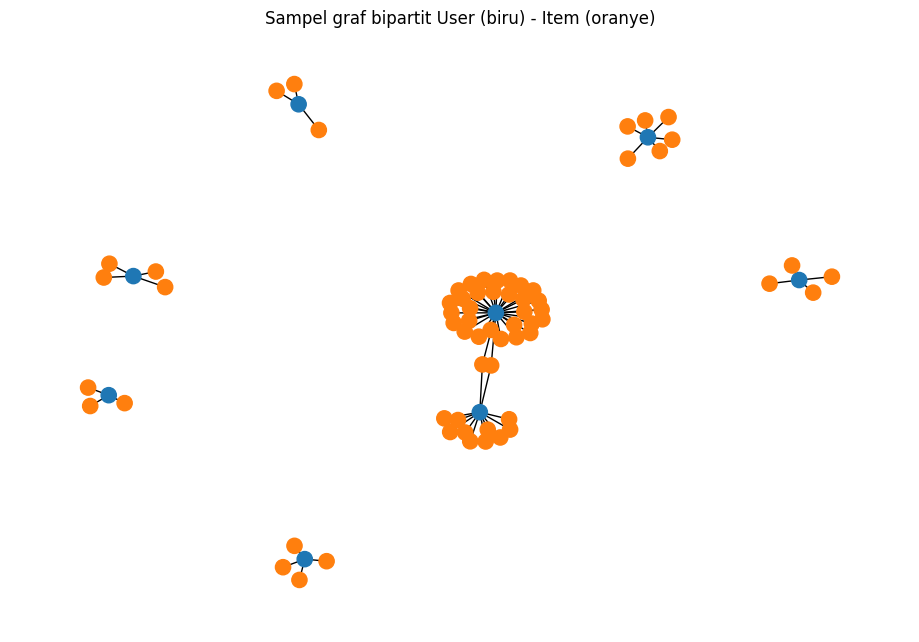

In [14]:
import networkx as nx, matplotlib.pyplot as plt

rng = np.random.default_rng(42)
sample_users = rng.choice(np.where(M.getnnz(axis=1) >= 3)[0], 8, replace=False)

G = nx.Graph()
for u in sample_users:
    for j in M[u].indices:
        G.add_edge(f"U{users[u]}", f"I{items[j]}")

colors = ["tab:blue" if n.startswith("U") else "tab:orange" for n in G.nodes]
plt.figure(figsize=(9, 6))
nx.draw(G, node_color=colors, node_size=120, with_labels=False)
plt.title("Sampel graf bipartit User (biru) - Item (oranye)")
plt.show()

**Plot networkx:** sampel 8 user (dengan ≥ 3 item) membentuk 7 komponen terpisah (73 simpul): tiap user (biru) terhubung ke item miliknya (oranye), dan hanya sedikit item yang dipakai bersama. Ini visualisasi langsung dari sparsity yang tinggi. Satu user di sampel memiliki 31 item (*hub*).

### No. 7: Similarity pada graf terproyeksi (Item–Item)
Tiap baris `Mᵀ` (vektor item) dinormalisasi L2, lalu `Mn · Mnᵀ` menghasilkan **cosine similarity** antar item; diagonal (item dengan dirinya sendiri) dihapus.

**Item acuan** dipilih otomatis dengan `argmax` jumlah tetangga (deterministik, bisa direproduksi): item **119736** dengan 2.171 tetangga. Skor 5 tertinggi: 215201 (0,6704), 424548 (0,6611), 437778 (0,5999), 359177 (0,5736), 422327 (0,5666).

In [15]:
from sklearn.preprocessing import normalize

Mt = M.T.tocsr().astype(float)
Mn = normalize(Mt)
S = (Mn @ Mn.T).tocsr()
S.setdiag(0); S.eliminate_zeros()

deg = S.getnnz(axis=1)
ref = int(np.argmax(deg))
print("Item acuan:", items[ref], "| jumlah tetangga:", deg[ref])

row = S[ref]
top = np.argsort(-row.data)[:5]
top5 = [(int(items[row.indices[k]]), float(row.data[k])) for k in top]
for it, sc in top5: print(it, round(sc, 4))

Item acuan: 119736 | jumlah tetangga: 2171
215201 0.6704
424548 0.6611
437778 0.5999
359177 0.5736
422327 0.5666


In [16]:
def count_sim():
    r, _, _ = driver.execute_query("MATCH ()-[s:SIMILAR]->() RETURN count(s) AS n", database_=DB)
    return r[0]["n"]

print("SIMILAR sebelum:", count_sim())

driver.execute_query("""
UNWIND $rows AS r
MATCH (a:Item {itemId: $ref}), (b:Item {itemId: r.item})
MERGE (a)-[s:SIMILAR]->(b) SET s.score = r.score
""", ref=int(items[ref]), rows=[{"item": i, "score": s} for i, s in top5], database_=DB)

print("SIMILAR sesudah:", count_sim())

SIMILAR sebelum: 0
SIMILAR sesudah: 5


### No. 7b & 8: Menuliskan similarity ke graf (sebelum dan sesudah)
```cypher
UNWIND $rows AS r
MATCH (a:Item {itemId: $ref}), (b:Item {itemId: r.item})
MERGE (a)-[s:SIMILAR]->(b) SET s.score = r.score
```
`UNWIND` mengurai daftar 5 tetangga, `MATCH` mencari simpul acuan dan tetangga, `MERGE` membuat relasi `SIMILAR` bila belum ada, dan `SET` menyimpan skor cosine sebagai properti relasi. Jumlah relasi `SIMILAR` **sebelum = 0, sesudah = 5**.

Query yang dijalankan di Neo4j Aura (tab Query) tersimpan di berkas terpisah:

| Soal | Berkas query | Bukti |
|---|---|---|
| 7a (top-5 similarity, graf) | `7a_sesudah_similarity_top5_graf.cypher` | gambar *sesudah* di bawah |
| 7b (nilai similarity, tabel) | `7b_tabel_similarity.cypher` | `Tabel_similarity.csv` |
| 8 (kondisi sebelum) | `8_sebelum_similarity.cypher` | gambar *sebelum* di bawah |

**Sebelum** perhitungan similarity: item 119736 hanya terhubung ke visitor lewat relasi `VIEWED`.

![Graf sebelum similarity](images/graf_sebelum.png)

**Sesudah** similarity ditulis: muncul 5 relasi `SIMILAR` dari 119736 ke item-item termirip.

![Graf sesudah similarity](images/graf_sesudah.png)

## 3. Analytics (Soal 2.2)
### No. 1: User acak dan KNN (k = 5)
- **Pemilihan user acak yang reproducible:** dari 942 user layak (ada di P1 dan P2, ≥ 3 item di P1, diurutkan), dipilih dengan `random.seed(42)` + `random.choice` → user **944589** (3 item di P1, 3 item di P2).
- **KNN item-based:** untuk setiap item yang pernah diinteraksi user di P1, diambil 5 tetangga (k = 5) dengan cosine tertinggi. Skor kandidat dijumlahkan dari semua item riwayat; item yang sudah ada di riwayat dibuang. Lima skor tertinggi menjadi rekomendasi.
- **Hasil:** top-5 = 136328, 72809, 244376, 150463, 390741. **3 item yang diiklankan: 136328, 72809, 244376.**

In [17]:
import random
from collections import defaultdict

both = set(p1.visitorid) & set(p2.visitorid)
cnt = p1[p1.visitorid.isin(both)].groupby("visitorid")["itemid"].nunique()
eligible = sorted(cnt[cnt >= 3].index.tolist())

SEED = 42
random.seed(SEED)
target = random.choice(eligible)
print("User target:", target, "(seed =", SEED, ")")

hist = set(p1[p1.visitorid == target]["itemid"].astype("int64"))
truth = set(p2[p2.visitorid == target]["itemid"].astype("int64"))
print("Item di P1:", len(hist), "| Item di P2 (ground truth):", len(truth))

K = 5
score = defaultdict(float)
for it in hist:
    j = i_idx[it]
    r = S[j]
    top = np.argsort(-r.data)[:K]
    for k in top:
        cand = int(items[r.indices[k]])
        if cand not in hist:
            score[cand] += float(r.data[k])

ranked = sorted(score.items(), key=lambda x: -x[1])
rec5 = [i for i, _ in ranked[:5]]
print("Top-5 rekomendasi:", rec5)
print("3 item yang diiklankan:", rec5[:3])

User target: 944589 (seed = 42 )
Item di P1: 3 | Item di P2 (ground truth): 3
Top-5 rekomendasi: [136328, 72809, 244376, 150463, 390741]
3 item yang diiklankan: [136328, 72809, 244376]


### No. 2: Evaluasi Hit@5 dan NDCG@5
- **Relevansi:** item apa pun yang diinteraksi user di P2 (view/addtocart/transaction), karena transaksi di P2 hanya 1.168 dari 140.752 event.
- **Hit@5** = 1 jika minimal satu dari 5 rekomendasi ada di ground truth, selain itu 0.
- **NDCG@5** = DCG / IDCG, dengan DCG = Σ 1 / log₂(posisi + 1) untuk rekomendasi yang relevan, dan IDCG = DCG ideal (semua item relevan berada di posisi teratas).

In [18]:
import math

def hit_at_k(rec, truth, k=5):
    return int(any(i in truth for i in rec[:k]))

def ndcg_at_k(rec, truth, k=5):
    dcg = sum(1 / math.log2(r + 2) for r, i in enumerate(rec[:k]) if i in truth)
    idcg = sum(1 / math.log2(r + 2) for r in range(min(len(truth), k)))
    return dcg / idcg if idcg > 0 else 0.0

print("Hit@5  :", hit_at_k(rec5, truth))
print("NDCG@5 :", round(ndcg_at_k(rec5, truth), 4))

Hit@5  : 0
NDCG@5 : 0.0


Untuk user 944589, **Hit@5 = 0 dan NDCG@5 = 0**: tidak ada dari 5 rekomendasi yang muncul di 3 item yang diinteraksi user ini di P2. Ini bukan kesalahan kode; satu user tidak cukup untuk menilai model, karena dari ±58.000 item hanya 5 yang direkomendasikan. Karena itu dihitung juga rata-rata atas seluruh user layak (sel berikut).

In [19]:
hits, ndcgs = [], []
for u in eligible:
    h = set(p1[p1.visitorid == u]["itemid"].astype("int64"))
    t = set(p2[p2.visitorid == u]["itemid"].astype("int64"))
    sc = defaultdict(float)
    for it in h:
        r = S[i_idx[it]]
        for k in np.argsort(-r.data)[:5]:
            c = int(items[r.indices[k]])
            if c not in h: sc[c] += float(r.data[k])
    rec = [i for i, _ in sorted(sc.items(), key=lambda x: -x[1])[:5]]
    hits.append(hit_at_k(rec, t)); ndcgs.append(ndcg_at_k(rec, t))
print("Rata2 Hit@5:", np.mean(hits).round(4), "| Rata2 NDCG@5:", np.mean(ndcgs).round(4))

Rata2 Hit@5: 0.0244 | Rata2 NDCG@5: 0.009


**Rata-rata atas 942 user: Hit@5 = 0,0244 (≈ 23 user) dan NDCG@5 = 0,009.**

Nilai ini rendah, dan penyebabnya jelas:
1. Sinyal kolaboratif sangat tipis: 81,8% user hanya punya 1 item di P1 dan sparsity 99,9975%.
2. Ruang kandidat sangat besar (58.530 item) dengan hanya 5 slot rekomendasi.
3. Pada 500 dari 942 user (±53%), item di P2 mencakup item yang **sudah dilihat user di P1** (kunjungan ulang), padahal rekomendasi sengaja mengecualikan item riwayat.

Sebagai pembanding, sel berikut menghitung baseline *item terpopuler di P1* (di luar riwayat user): **Hit@5 = 0,0021 dan NDCG@5 = 0,0004**. KNN item-based sekitar 11× (Hit@5) dan 22× (NDCG@5) lebih baik daripada baseline populer, walau nilai absolutnya kecil.

In [20]:
pop = p1.groupby("itemid").size().sort_values(ascending=False, kind="stable")
pop_list = [int(i) for i in pop.index]

hp, np_ = [], []
for u in eligible:
    h = set(p1[p1.visitorid == u]["itemid"].astype("int64"))
    t = set(p2[p2.visitorid == u]["itemid"].astype("int64"))
    rec = [i for i in pop_list if i not in h][:5]
    hp.append(hit_at_k(rec, t)); np_.append(ndcg_at_k(rec, t))
print("Baseline populer  Hit@5:", np.mean(hp).round(4), "| NDCG@5:", np.mean(np_).round(4))


Baseline populer  Hit@5: 0.0021 | NDCG@5: 0.0004


## 4. Periode dalam UNIX timestamp (untuk Google Form)
Dataset memakai milidetik; periode P1/P2 di atas dikonversi dengan `pd.Timestamp(...)` (UTC).

In [21]:
import pandas as pd

periode = {
    "P1 mulai":   "2015-05-18 00:00:00",
    "P1 selesai": "2015-05-25 23:59:59",
    "P2 mulai":   "2015-05-26 00:00:00",
    "P2 selesai": "2015-06-01 23:59:59",
}
for nama, t in periode.items():
    ms = int(pd.Timestamp(t).timestamp() * 1000)
    print(nama, "->", ms)

P1 mulai -> 1431907200000
P1 selesai -> 1432598399000
P2 mulai -> 1432598400000
P2 selesai -> 1433203199000


## 5. Kesimpulan dan keterbatasan
- Graf bipartit Visitor–Item (96.733 + 58.530 simpul, 176.376 relasi) berhasil dibangun di Neo4j dari periode P1 (18–25 Mei 2015); data training (176.376 baris) lebih banyak daripada data testing P2 (140.752 baris).
- Proyeksi **Item–Item** dipilih karena dimensinya lebih kecil dan densitasnya lebih tinggi; cosine similarity ditulis kembali ke graf sebagai relasi `SIMILAR`.
- KNN item-based memberi rata-rata Hit@5 = 0,0244 dan NDCG@5 = 0,009 pada 942 user, jauh lebih baik daripada baseline item terpopuler (0,0021 dan 0,0004), namun nilainya masih kecil.
- **Keterbatasan:** P1 hanya 8 hari (batas AuraDB Free); sparsity 99,9975%; bobot event (1/3/5) adalah asumsi; relevansi P2 mencakup semua jenis interaksi dan sebagian berupa kunjungan ulang; evaluasi memakai satu pembagian waktu saja; urutan di antara skor yang sama dapat berbeda antar platform sehingga angka rata-rata bisa bergeser sedikit.